# Annotating clusters of a targeted marker panel from a marker knowledge base

Multiplexed imaging (CODEX / PhenoCycler, MIBI, IMC, CyCIF, multiplex IF) and
targeted in-situ panels measure **a few dozen markers per cell**, not a
transcriptome. After segmentation and clustering, every cluster has to be
named from a handful of markers — and in practice this step is usually done
by eye, with a marker table typed into the analysis script. That is where
most irreproducibility in panel studies comes from: the table encodes one
person's memory of the literature, an antibody name is silently mapped to the
wrong gene, and a cluster that fits nothing well is quietly forced into the
nearest label.

`ov.space` splits the job into reproducible, auditable steps:

| Step | Function | What it does |
|---|---|---|
| panel names → genes | `ov.space.panel_gene_map` | resolves antibody / protein names ("CD20", "E-cadherin", "Granzyme B") to HGNC gene symbols through HGNC, MyGene.info, UniProt and the Antibody Registry, and reports *how* each name was matched |
| labels → signed signatures | `ov.space.markerdb_signatures` | builds `{label: {marker: weight}}` from a **marker knowledge base** (the OmicosAnno atlas: positive *and* negative markers with the number of supporting papers), the Cell Ontology hierarchy (`parents`, inherited markers) and opposed sibling pairs (`polar`) |
| cluster statistics | `ov.space.cluster_marker_profile` | per-cluster means, positive fractions (Otsu per marker), cross-cluster z-scores, stand-out markers |
| scoring | `ov.space.score_cluster_signatures` | presence test → best signature → children resolved inside their parent → residual ("unassigned") label; every call carries its evidence and a `review` flag |
| spatial context | `ov.space.cluster_neighbor_composition` | what each cluster's cells are surrounded by — supporting evidence and the basis for re-assigning clusters with no usable signature |
| deliverable | `ov.space.write_cluster_labels` / `ov.space.audit_cluster_labels` | write the cluster → label table straight from the scorer, accept manual overrides **only** for clusters the scorer left open (with written evidence), keep a sidecar audit file, and re-check a deliverable later |

The principle: **the biology comes from a database, the decisions come from
the data, and every deviation is written down.** No marker table is typed
into this notebook.

**When to use it.** Any cells × markers table with cluster ids — protein
panels (arcsinh-transformed intensities) or small targeted RNA panels. For
whole-transcriptome data use the reference-based or marker-gene annotation
tutorials instead.

**Data in this tutorial.** We simulate a colon-mucosa-like CODEX section
(epithelium, stroma with vessels and smooth muscle, a lymphoid aggregate)
measured with a 20-antibody panel. The marker programme of every cell type
is *generated from the fetched knowledge-base signatures*, with realistic
intensity noise, lateral spill-over between touching cells and a population
that matches no label, so we know the ground truth and can score the
annotation.

## 1. Setup

`markerdb_signatures` queries public services (HGNC, MyGene.info, EBI OLS,
UniProt, Antibody Registry) and the OmicosAnno marker atlas. The atlas
marker endpoint needs an **OmicOS account token** in the environment
variable `OMICOS_USER_TOKEN` (OmicOS kernels inject it automatically;
elsewhere export it before starting Jupyter — never paste it into a
notebook). Every network result is stored in the JSON file given as
`cache=`, so re-running the notebook, or sharing the cache with a
collaborator, needs no further network access.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import omicverse as ov

ov.plot_set()
pd.set_option('display.max_colwidth', 110)
print('OMICOS_USER_TOKEN set:', bool(os.environ.get('OMICOS_USER_TOKEN')))
CACHE = 'markerdb_cache.json'

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.

OMICOS_USER_TOKEN set: True


## 2. From antibody names to genes: `panel_gene_map`

Panel columns are named after antibodies, not genes: `CD20` is *MS4A1*,
`CD31` is *PECAM1*, `E-cadherin` is *CDH1*. Knowledge bases are indexed by
gene, so the first step is nomenclature. `panel_gene_map` tries the
approved HGNC symbol first, then HGNC aliases / previous symbols, then
MyGene.info, symbol stems (`CD3` → the CD3 chains), gene families and
protein names. The `sources` dict tells you **which rule matched** each
name — anything other than `symbol` deserves a look.

In [2]:
panel = ['CD45', 'CD3', 'CD4', 'CD8', 'FOXP3', 'CD20', 'CD68', 'CD163', 'CD11c',
         'HLA-DR', 'CD56', 'Pan-Cytokeratin', 'E-cadherin', 'Vimentin', 'aSMA',
         'CD31', 'Podoplanin', 'Ki67', 'Granzyme B', 'Collagen IV']

sources = {}
gene_map, unresolved = ov.space.panel_gene_map(panel, sources=sources)
gm_table = pd.DataFrame({'genes': [', '.join(gene_map.get(m, [])) for m in panel],
                         'matched by': [sources.get(m, '-') for m in panel]}, index=panel)
print('unresolved:', unresolved)
gm_table

unresolved: ['HLA-DR', 'Pan-Cytokeratin', 'Collagen IV']


                                  genes matched by
CD45                              PTPRC      alias
CD3              CD3D, CD3E, CD3G, CD3W       stem
CD4                                 CD4     symbol
CD8                                CD8A      alias
FOXP3                             FOXP3     symbol
CD20                              MS4A1      alias
CD68                               CD68     symbol
CD163                             CD163     symbol
CD11c                             ITGAX      alias
HLA-DR                                           -
CD56                              NCAM1      alias
Pan-Cytokeratin                                  -
E-cadherin                         CDH1       name
Vimentin               VIM, VIM2P, VMAC       name
aSMA                              ACTA2   antibody
CD31                             PECAM1      alias
Podoplanin                         PDPN       name
Ki67                              MKI67      alias
Granzyme B                     

Most names resolve through nomenclature. Three rows are worth reading:

* **`aSMA` → `ACTA2`, matched by `antibody`.** A name led by a lower-case
  Greek letter is a protein-name abbreviation (α-SMA, alpha-smooth-muscle
  actin), not a gene symbol, so it is resolved through its spelled-out
  name: HGNC and UniProt names first, then the UniProt target that the
  antibodies registered under that name (Antibody Registry, RRID) declare.
  A case-insensitive alias lookup would return *ACTA1* instead: NCBI lists
  `ASMA` (alpha-*skeletal*-muscle actin) as an ACTA1 alias. That is why
  `matched by` matters: anything other than `symbol` deserves a look.
* **`Ki67` → `MKI67`** through the nomenclature spelling `Ki-67`.
* **Unresolved names** (`Pan-Cytokeratin`, `HLA-DR`, `Collagen IV` here)
  match several genes or none. Without a gene they cannot carry
  knowledge-base evidence. `markerdb_signatures` retries such names
  against UniProt protein names and the Antibody Registry and disambiguates
  multi-gene hits by how often each gene is used as a marker in the atlas.

Nomenclature fixes are the **only** manual input allowed:
`gene_overrides={marker: [genes]}` states which protein an antibody
detects (`protein_names={marker: full protein name}` is the alternative
when you would rather let HGNC pick the gene from the protein's name);
neither ever says which cell type a marker belongs to. This panel needs
neither.

### 2b. When a nomenclature service fails: `failed=` and `kb['lookup_failed']`

Every name is resolved through public web services. A rate limit or an
outage must not be read as "this name has no gene": a defining marker would
silently drop out of every signature, and every downstream call could still
look confident. Requests are therefore retried with backoff; a name whose
lookup still hits a network / service error is reported — by
`panel_gene_map` in the list passed as `failed=`, by `markerdb_signatures`
in `kb['lookup_failed']` with a warning — and is **not cached**, so calling
again with the same cache retries exactly those names. With the services
up, the list is empty:

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import omicverse as ov

failed = []
gm, unresolved = ov.space.panel_gene_map(['CD20', 'Ki67', 'PD-L1', 'CD68'], failed=failed)
print('gene map        :', gm)
print('unresolved      :', unresolved)
print('failed lookups  :', failed)

gene map        : {'CD20': ['MS4A1'], 'Ki67': ['MKI67'], 'PD-L1': ['CD274'], 'CD68': ['CD68']}
unresolved      : []
failed lookups  : []


Make it a rule of the pipeline: if `kb['lookup_failed']` is not empty,
wait and call `markerdb_signatures` again with the same arguments and cache
until it is — never score with a panel whose names could not be looked
up.

## 3. Signed signatures from the marker knowledge base: `markerdb_signatures`

We give the cell-type **vocabulary** we want to use (a study's label set,
deliberately including a parent `T cell` and three of its subtypes) and the
panel. For every label the function

1. matches the label to an atlas cell type and a Cell Ontology (CL) term;
2. pulls its **positive and negative** marker statements with their paper
   counts; a statement's weight is its support relative to the label's
   best-supported marker (the defining marker weighs 1);
3. lets a label inherit the markers of its CL ancestors (down-weighted per
   generation) — a Treg carries the T-cell markers its own papers rarely
   restate;
4. derives `parents` (here from the label wording: `CD8-positive T cell`
   sits under `T cell`) and `polar` sibling pairs (each one's defining marker
   is a *negative* marker of the other — CD4 vs CD8);
5. keeps only the markers on this panel.

First, to see what a wrong paralogue does downstream, we force the mapping
a case-insensitive alias lookup would give, `aSMA` → *ACTA1*, through
`gene_overrides` (the hook for correcting nomenclature by hand):

In [3]:
labels = ['T cell', 'CD4-positive T cell', 'CD8-positive T cell', 'regulatory T cell',
          'B cell', 'macrophage', 'dendritic cell', 'natural killer cell',
          'epithelial cell', 'endothelial cell', 'fibroblast', 'smooth muscle cell']

kb_raw = ov.space.markerdb_signatures(labels, panel, species='human', cache=CACHE,
                                      gene_overrides={'aSMA': ['ACTA1']})
print('weak signatures      :', kb_raw['weak_signatures'])
print('smooth muscle (raw)  :', {m: round(w, 2) for m, w in kb_raw['signatures']['smooth muscle cell'].items()})

weak signatures      : ['smooth muscle cell']
smooth muscle (raw)  : {'aSMA': 0.1, 'CD56': 0.02}


`smooth muscle cell` is reported in `weak_signatures`: its strongest marker
on this panel weighs far less than a typical label's defining marker,
because the panel's `aSMA` column was mapped to skeletal actin, which the
atlas barely links to smooth muscle. A weak signature cannot compete for
clusters, and nothing raises an error. Now with the panel as
`panel_gene_map` resolves it, without any manual input:

In [4]:
kb = ov.space.markerdb_signatures(labels, panel, species='human', cache=CACHE)
print('aSMA, Ki67 genes  :', kb['gene_map']['aSMA'], kb['gene_map']['Ki67'])
print('weak signatures   :', kb['weak_signatures'])
print('unresolved markers:', kb['unresolved_markers'])
print('parents           :', kb['parents'])
print('polar             :', kb['polar'])
print('defining          :', kb['defining'])
print('remapped markers  :', {m: v['now'] for m, v in kb['remapped_markers'].items()})

aSMA, Ki67 genes  : ['ACTA2'] ['MKI67']
weak signatures   : []
unresolved markers: []
parents           : {'CD4-positive T cell': 'T cell', 'CD8-positive T cell': 'T cell', 'regulatory T cell': 'T cell'}
polar             : {'T cell': ['CD4-positive T cell', 'CD8-positive T cell', 'regulatory T cell']}
defining          : {'T cell': ['CD3'], 'CD4-positive T cell': ['CD4'], 'CD8-positive T cell': ['CD8'], 'regulatory T cell': ['FOXP3'], 'B cell': ['CD20'], 'macrophage': ['CD68'], 'dendritic cell': ['CD11c'], 'natural killer cell': ['CD56'], 'epithelial cell': ['E-cadherin'], 'endothelial cell': ['CD31'], 'fibroblast': ['Vimentin'], 'smooth muscle cell': ['aSMA']}
remapped markers  : {'Pan-Cytokeratin': ['KRT19']}


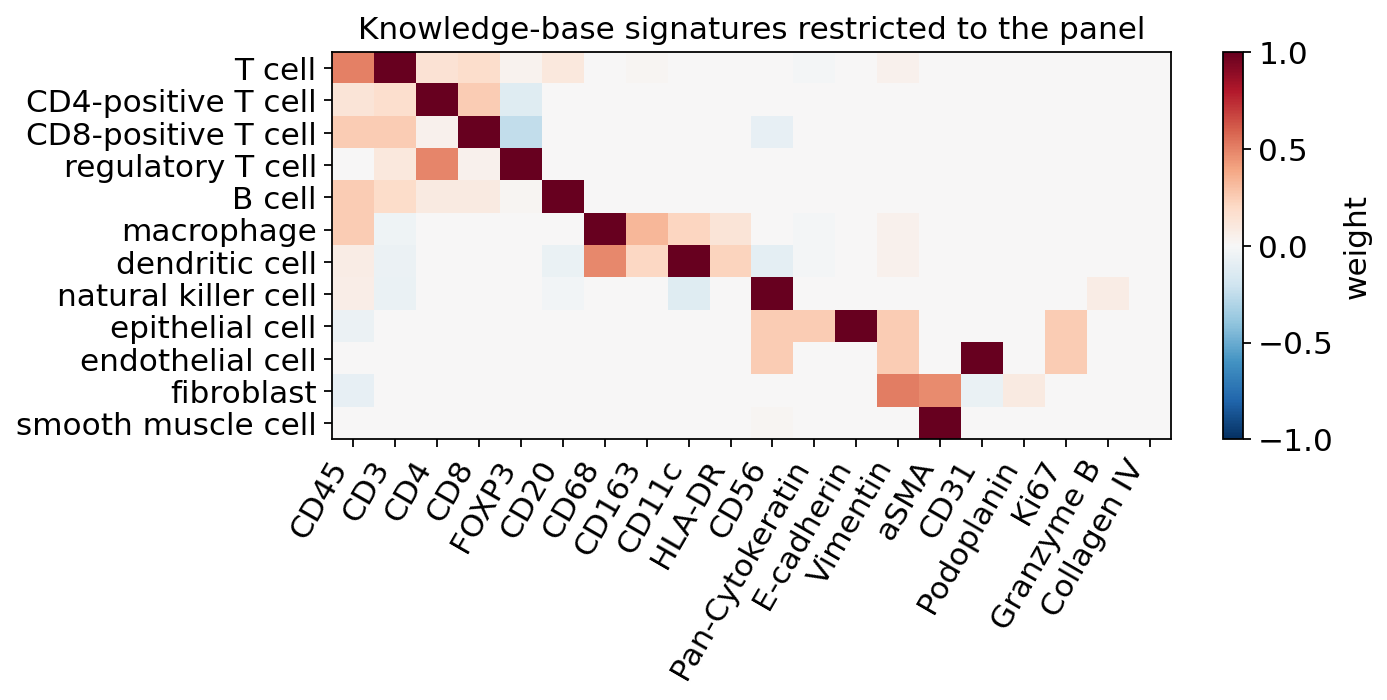

In [5]:
sig = pd.DataFrame(kb['signatures']).T.reindex(columns=panel).fillna(0.0)
fig, ax = plt.subplots(figsize=(9, 4.6))
im = ax.imshow(sig.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(sig.shape[1])); ax.set_xticklabels(sig.columns, rotation=60, ha='right')
ax.set_yticks(range(sig.shape[0])); ax.set_yticklabels(sig.index)
fig.colorbar(im, ax=ax, label='weight')
ax.set_title('Knowledge-base signatures restricted to the panel')
plt.tight_layout(); plt.show()

With *ACTA2* no signature is weak and every panel name has a gene.
Note `remapped markers`: `Pan-Cytokeratin` (a cocktail of keratins that
nomenclature alone cannot resolve) was mapped through the Antibody Registry
to *KRT19*, the keratin the atlas uses most for the label set.

How to read the signature matrix:

* most rows have one marker at weight 1 — the label's best-supported marker
  (CD3 for T cells, CD20 for B cells, CD31 for endothelium, aSMA for smooth
  muscle now that it maps to *ACTA2*). The fibroblast row peaks at about
  0.5: its best-supported atlas markers are not on this panel, and only
  Vimentin and aSMA (myofibroblasts) carry it here;
* secondary markers carry their support *relative* to it: a marker named in
  a handful of papers next to one named in hundreds weighs little, so an
  incidental mention cannot decide a call;
* **blue cells are negative markers** — e.g. FOXP3 argues against a
  cytotoxic CD8 T cell; they penalise a label in clusters that express them;
* the subtypes carry their parent's CD3 through ontology inheritance.

`gene_check` lists, per panel name, the genes used, their approved names
and how much the atlas uses them — the table to review before trusting a
mapping (indirect matches that define no label come first):

In [6]:
pd.DataFrame(kb['gene_check']).head(8)

            marker                genes  \
0      Collagen IV             [COL4A1]   
1           HLA-DR  [HLA-DRA, HLA-DRB1]   
2       Podoplanin               [PDPN]   
3       Granzyme B               [GZMB]   
4  Pan-Cytokeratin              [KRT19]   
5            CD163              [CD163]   
6             Ki67              [MKI67]   
7             CD45              [PTPRC]   

                                                                                                           names  \
0                                                                               [collagen type IV alpha 1 chain]   
1  [major histocompatibility complex, class II, DR alpha, major histocompatibility complex, class II, DR beta 1]   
2                                                                                                   [podoplanin]   
3                                                                                                   [granzyme B]   
4                               

## 4. A simulated CODEX section with known cell types

We lay out a 1 mm² piece of colon mucosa: an epithelial band, stroma with
fibroblasts, macrophages, dendritic cells, a smooth-muscle layer and small
vessels, and a lymphoid aggregate (B-cell follicle surrounded by CD4, CD8 and
regulatory T cells, with scattered NK cells). A twelfth population,
`other`, expresses none of the panel's lineage markers (think of stromal
cells the panel was not designed for) — the honest answer for it is
*unassigned*.

Each cell type's expected marker level is taken from its knowledge-base
signature (positive weights; negative markers at background). Measured
intensities then get what real imaging adds: a background level, cell-to-
cell log-normal variation, **lateral spill-over** (15 % of each cell's
signal comes from its touching neighbours — the main source of
mis-annotation in segmented imaging data) and Poisson counting noise.

In [7]:
rng = np.random.default_rng(7)
pops = []                                   # (label, n, sampler)

def band(n, y0, y1):
    return np.c_[rng.uniform(0, 1000, n), rng.uniform(y0, y1, n)]

def blob(n, cx, cy, r):
    a = rng.uniform(0, 2 * np.pi, n); d = r * np.sqrt(rng.uniform(0, 1, n))
    return np.c_[cx + d * np.cos(a), cy + d * np.sin(a)]

def ring(n, cx, cy, r0, r1):
    a = rng.uniform(0, 2 * np.pi, n); d = np.sqrt(rng.uniform(r0**2, r1**2, n))
    return np.c_[cx + d * np.cos(a), cy + d * np.sin(a)]

layout = {
    'epithelial cell':     band(1500, 0, 280),
    'smooth muscle cell':  band(320, 900, 960),
    'fibroblast':          band(700, 300, 880),
    'macrophage':          band(350, 290, 880),
    'dendritic cell':      band(150, 290, 880),
    'endothelial cell':    np.vstack([blob(50, x, y, 25) for x, y in
                                      rng.uniform([60, 330], [940, 860], size=(6, 2))]),
    'other':               band(250, 300, 880),
    'B cell':              blob(600, 650, 600, 120),
    'CD4-positive T cell': ring(500, 650, 600, 120, 220),
    'CD8-positive T cell': ring(350, 650, 600, 120, 230),
    'regulatory T cell':   ring(120, 650, 600, 110, 220),
    'natural killer cell': band(100, 300, 880),
}
truth = np.concatenate([[k] * len(v) for k, v in layout.items()])
xy = np.vstack(list(layout.values()))

# expected marker programme of each true type, from the knowledge base
S = pd.DataFrame(kb['signatures']).T.reindex(columns=panel).fillna(0.0).clip(lower=0)
S.loc['other'] = 0.0
for child, parent in kb['parents'].items():          # a subtype also shows its lineage markers
    S.loc[child] = np.maximum(S.loc[child], S.loc[parent])
mu = S.loc[truth].to_numpy() + 0.04                    # + background
own = 250 * mu * rng.lognormal(0, 0.35, size=mu.shape)

from scipy.spatial import cKDTree
nbrs = cKDTree(xy).query_ball_point(xy, r=12)
spill = np.array([own[[j for j in js if j != i]].mean(0) if len(js) > 1 else np.zeros(len(panel))
                  for i, js in enumerate(nbrs)])
counts = rng.poisson(0.85 * own + 0.15 * spill).astype(float)
cells = pd.DataFrame(counts, columns=panel)
cells['x'], cells['y'], cells['truth'] = xy[:, 0], xy[:, 1], truth
print(cells.shape)
cells['truth'].value_counts()

(5240, 23)


truth
epithelial cell        1500
fibroblast              700
B cell                  600
CD4-positive T cell     500
CD8-positive T cell     350
macrophage              350
smooth muscle cell      320
endothelial cell        300
other                   250
dendritic cell          150
regulatory T cell       120
natural killer cell     100
Name: count, dtype: int64

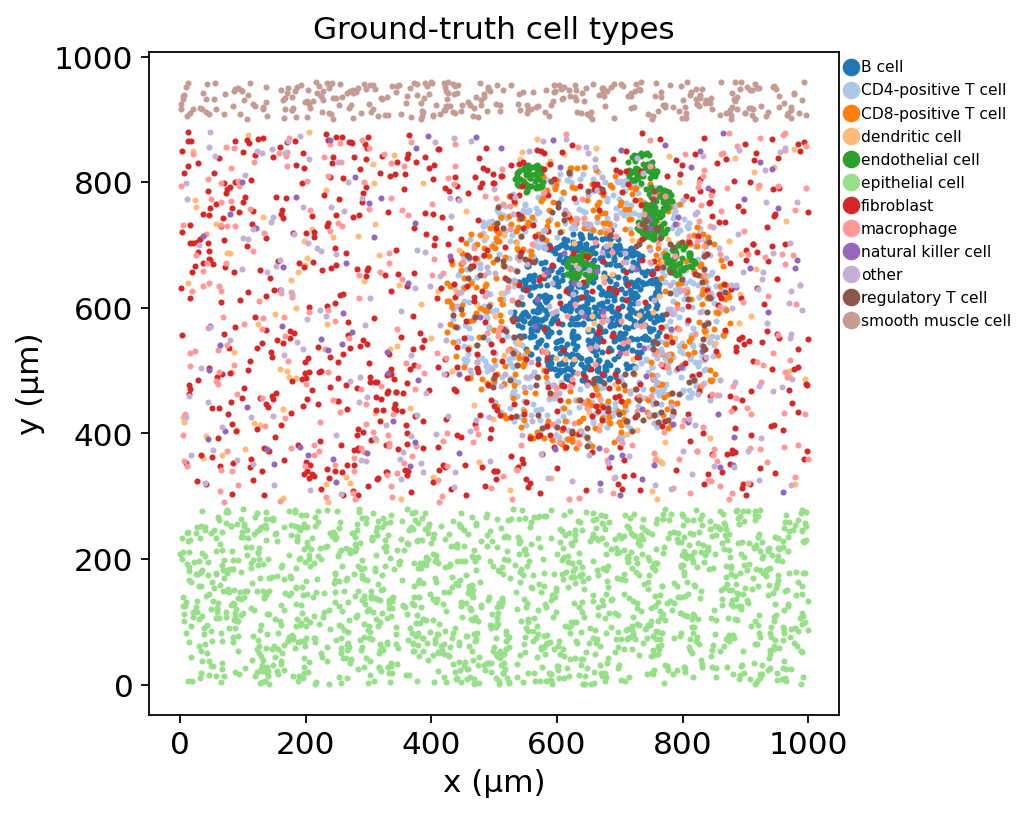

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 6))
pal = dict(zip(sorted(layout), plt.cm.tab20.colors))
for t in sorted(layout):
    m = cells.truth == t
    ax.scatter(cells.x[m], cells.y[m], s=3, color=pal[t], label=t)
ax.set_aspect('equal'); ax.set_xlabel('x (µm)'); ax.set_ylabel('y (µm)')
ax.set_title('Ground-truth cell types'); ax.legend(markerscale=4, fontsize=7, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

## 5. Cluster the cells, then profile the clusters: `cluster_marker_profile`

Clustering is not the subject here; we use k-means on arcsinh-transformed,
per-marker-scaled intensities with deliberately **more clusters (16) than
cell types** — the usual practice, because a parent lineage that the
clustering splits is what lets the scorer resolve its subtypes.

In [9]:
from sklearn.cluster import KMeans
Z = np.arcsinh(cells[panel] / 5.0)
Z = Z / Z.quantile(0.999)
cells['cluster'] = KMeans(16, n_init=10, random_state=0).fit_predict(Z.clip(0, 1)).astype(str)

prof = ov.space.cluster_marker_profile(cells[panel + ['cluster']], 'cluster')
print('arcsinh applied automatically (raw counts detected); markers:', len(prof.attrs['markers']))
prof[['n_cells']].T

arcsinh applied automatically (raw counts detected); markers: 20


           0    1   10  11   12   13  14   15    2    3    4    5    6    7  \
n_cells  120  690  810  54  119  100  76  503  500  358  271  343  300  347   

           8    9  
n_cells  329  320  

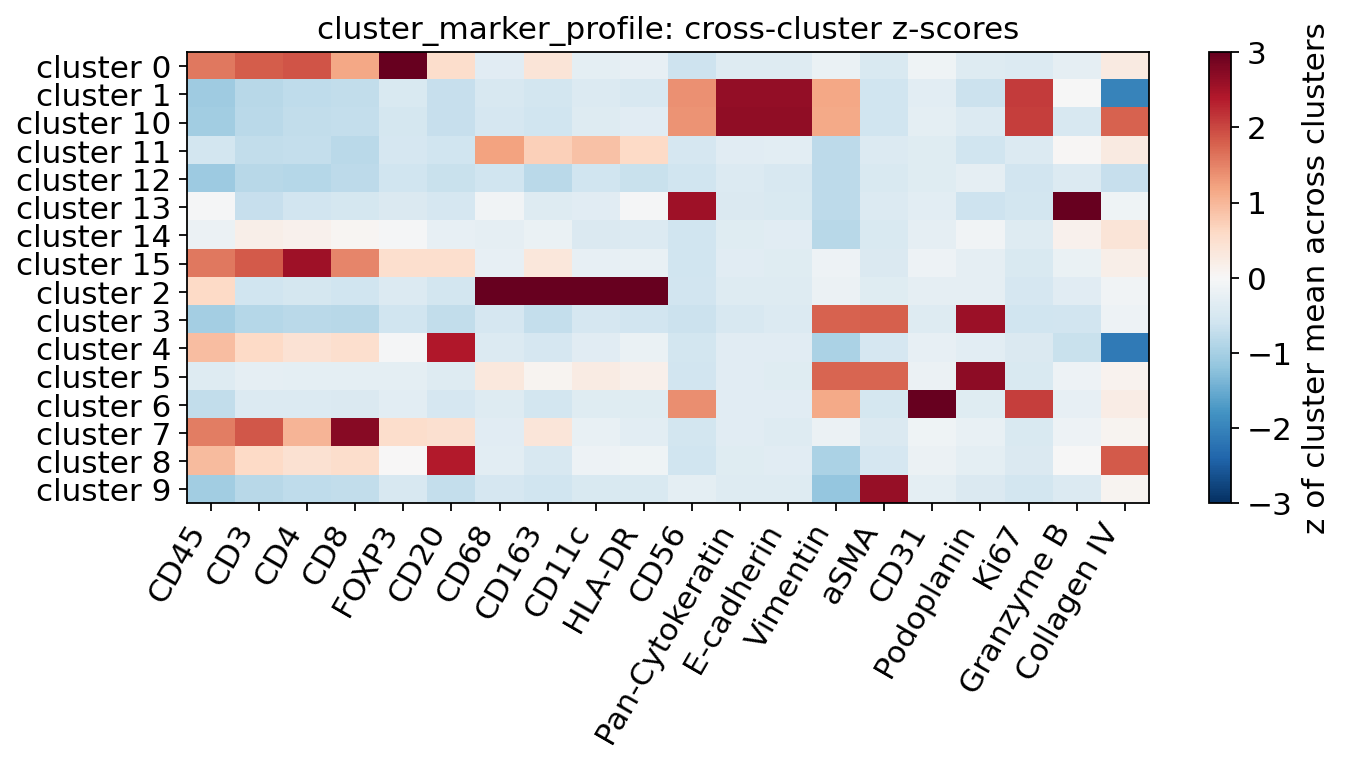

                                 stand-out markers
0                            FOXP3, CD4, CD3, CD45
1                E-cadherin, Pan-Cytokeratin, Ki67
10  Pan-Cytokeratin, E-cadherin, Ki67, Collagen IV
11                                                
12                                                
13                                Granzyme B, CD56
14                                                
15                                  CD4, CD3, CD45
2                       HLA-DR, CD11c, CD68, CD163
3                       Podoplanin, aSMA, Vimentin
4                                             CD20
5                       Podoplanin, Vimentin, aSMA
6                                       CD31, Ki67
7                                   CD8, CD3, CD45
8                                CD20, Collagen IV
9                                             aSMA

In [10]:
zmat = prof.filter(like='z:').rename(columns=lambda c: c[2:])
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(zmat.values, cmap='RdBu_r', vmin=-3, vmax=3, aspect='auto')
ax.set_xticks(range(zmat.shape[1])); ax.set_xticklabels(zmat.columns, rotation=60, ha='right')
ax.set_yticks(range(zmat.shape[0])); ax.set_yticklabels([f'cluster {c}' for c in zmat.index])
fig.colorbar(im, ax=ax, label='z of cluster mean across clusters')
ax.set_title('cluster_marker_profile: cross-cluster z-scores')
plt.tight_layout(); plt.show()
pd.Series({c: ', '.join(v[:4]) for c, v in prof.attrs['standout'].items()}, name='stand-out markers').to_frame()

The profile holds, for every cluster and marker, the scaled mean (`mean:`),
the mean relative to the brightest cluster (`rel:`), the cross-cluster z
(`z:`) and the fraction of Otsu-positive cells (`pos:`). Intensities were
raw counts, so `transform='auto'` applied `arcsinh(x/5)` before scaling
every marker to its 99.9th percentile — markers with very different dynamic
ranges become comparable. The **stand-out markers** (z ≥ 1.5) are what a
human would read off the heatmap: one cluster is CD20-high, another
CD31-high, one is high on nothing.

## 6. Score the signatures: `score_cluster_signatures`

The scorer does what a careful annotator does, in a fixed order:

1. **presence** — a top-level label is eligible for a cluster only if its
   defining markers are measured and one of them is clearly present;
2. **best signature** — eligible labels are scored with an l2 "matched
   filter" over the weighted markers (negative markers subtract);
3. **children inside their parent** — subtypes only compete among the
   clusters already given to their parent; with `polar`, clusters leaning to
   opposite poles (CD4 vs CD8) take one pole each;
4. **residual** — clusters that support no signature get `residual_label`
   instead of the least-bad guess.

Every cluster also gets its evidence: `lineage_z` (z of the winner's best
defining marker), the runner-up candidates, and `review` = `fixed` or
`open: …` when the evidence is below the dataset mean or another candidate
has stronger lineage evidence.

In [11]:
res = ov.space.score_cluster_signatures(
    prof, kb['signatures'], parents=kb['parents'], polar=kb['polar'],
    defining=kb['defining'], residual_label='unassigned')
print('panel markers no signature uses:', res.attrs['unmatched'])
show = ['n_cells', 'top_label', 'label', 'lineage_z', 'review']
res.assign(n_cells=prof['n_cells'])[show]

panel markers no signature uses: []


    n_cells            top_label                label  lineage_z  \
0       120               T cell    regulatory T cell   3.638068   
1       690      epithelial cell      epithelial cell   2.638878   
10      810      epithelial cell      epithelial cell   2.648582   
11       54       dendritic cell       dendritic cell   0.890417   
12      119                 None           unassigned        NaN   
13      100  natural killer cell  natural killer cell   2.554502   
14       76               T cell               T cell   0.171481   
15      503               T cell  CD4-positive T cell   2.542848   
2       500       dendritic cell       dendritic cell   3.634459   
3       358           fibroblast           fibroblast   1.776709   
4       271               B cell               B cell   2.395793   
5       343           fibroblast           fibroblast   1.742521   
6       300     endothelial cell     endothelial cell   3.859584   
7       347               T cell  CD8-positive T

Each row is one cluster: `top_label` is the first-pass lineage, `label` the
final call after subtypes were resolved. Now the part a real dataset never
gives us — compare with the truth. A call counts as **exact** when it equals
the majority true type of the cluster and as **coarser** when it is that
type's parent (a T-cell cluster called `T cell` is correct but less
specific).

In [12]:
maj = cells.groupby('cluster')['truth'].agg(lambda s: s.value_counts().index[0])
purity = cells.groupby('cluster')['truth'].agg(lambda s: s.value_counts(normalize=True).iloc[0])
truth_label = maj.replace({'other': 'unassigned'})

def grade(c):
    call, t = res.at[c, 'label'], truth_label[c]
    if call == t:
        return 'exact'
    if kb['parents'].get(t) == call:
        return 'coarser'
    return 'wrong'

check = pd.DataFrame({'majority truth': maj, 'purity': purity.round(2),
                      'call': res['label'], 'grade': [grade(c) for c in res.index]})
cells['label'] = cells['cluster'].map(res['label'])
cell_truth = cells['truth'].replace({'other': 'unassigned'})
exact = (cells['label'] == cell_truth).mean()
lineage = ((cells['label'] == cell_truth) |
           (cells['label'] == cell_truth.map(lambda t: kb['parents'].get(t, t)))).mean()
print(f'cell-level accuracy: exact {exact:.1%}; exact or parent lineage {lineage:.1%}')
check.sort_values('grade')

cell-level accuracy: exact 90.8%; exact or parent lineage 90.8%


         majority truth  purity                 call  grade
0     regulatory T cell    1.00    regulatory T cell  exact
1       epithelial cell    1.00      epithelial cell  exact
10      epithelial cell    1.00      epithelial cell  exact
12                other    1.00           unassigned  exact
13  natural killer cell    1.00  natural killer cell  exact
15  CD4-positive T cell    0.99  CD4-positive T cell  exact
3            fibroblast    1.00           fibroblast  exact
4                B cell    1.00               B cell  exact
5            fibroblast    1.00           fibroblast  exact
6      endothelial cell    1.00     endothelial cell  exact
7   CD8-positive T cell    1.00  CD8-positive T cell  exact
8                B cell    1.00               B cell  exact
9    smooth muscle cell    1.00   smooth muscle cell  exact
11                other    1.00       dendritic cell  wrong
14                other    1.00               T cell  wrong
2            macrophage    0.70       de

Thirteen of sixteen clusters get exactly the right name, including the
three T-cell subtypes resolved inside their parent and the cluster of
marker-less cells left `unassigned`. The three failures are the
instructive part:

* **A mixed cluster.** One cluster is 70 % macrophages and 30 % dendritic
  cells (`purity` 0.70) and is called `dendritic cell`. The two share CD68,
  CD11c, HLA-DR and CD163 in the knowledge base, and k-means did not
  separate them. No label is right for a mixture — the fix is upstream
  (more clusters, or sub-clustering this one), not a relabel.
* **A featureless population split three ways.** k-means cut the 250
  `other` cells into three clusters. One is correctly `unassigned`; one is
  called `dendritic cell` but flagged `open` (its CD11c z is 0.9, below
  the macrophage candidate's CD68 z of 1.2); the third, a small cluster
  with no stand-out marker, is called `T cell` with lineage evidence
  `lineage_z` ≈ 0.2 — just above the dataset mean, so it is `fixed` under
  the default policy.

Read `lineage_z` together with the label: a call whose defining marker is
barely above the dataset mean is weak even when it is not flagged, and a
cluster with an empty stand-out list deserves a second look.

The ranked alternatives per cluster are kept in `candidates`, with the
z-scores of each candidate's defining markers — this is what you read when
a call is `open`:

In [13]:
res[['label', 'candidates']].head(6)

                  label  \
0     regulatory T cell   
1       epithelial cell   
10      epithelial cell   
11       dendritic cell   
12           unassigned   
13  natural killer cell   

                                                                                                       candidates  
0   T cell 4.30 [CD3 z=1.8 | via regulatory T cell: FOXP3 z=3.6; CD4-positive T cell: CD4 z=1.9] | B cell 1.51...  
1   epithelial cell 4.02 [E-cadherin z=2.6] | natural killer cell 1.38 [CD56 z=1.4] | endothelial cell 0.78 [C...  
10  epithelial cell 4.01 [E-cadherin z=2.6] | natural killer cell 1.32 [CD56 z=1.4] | endothelial cell 0.77 [C...  
11                                               dendritic cell 1.50 [CD11c z=0.9] | macrophage 1.40 [CD68 z=1.2]  
12                                                                                                                 
13  natural killer cell 2.86 [CD56 z=2.6] | endothelial cell -0.01 [CD31 z=-0.3] | epithelial cell -0.23 [E-ca... 

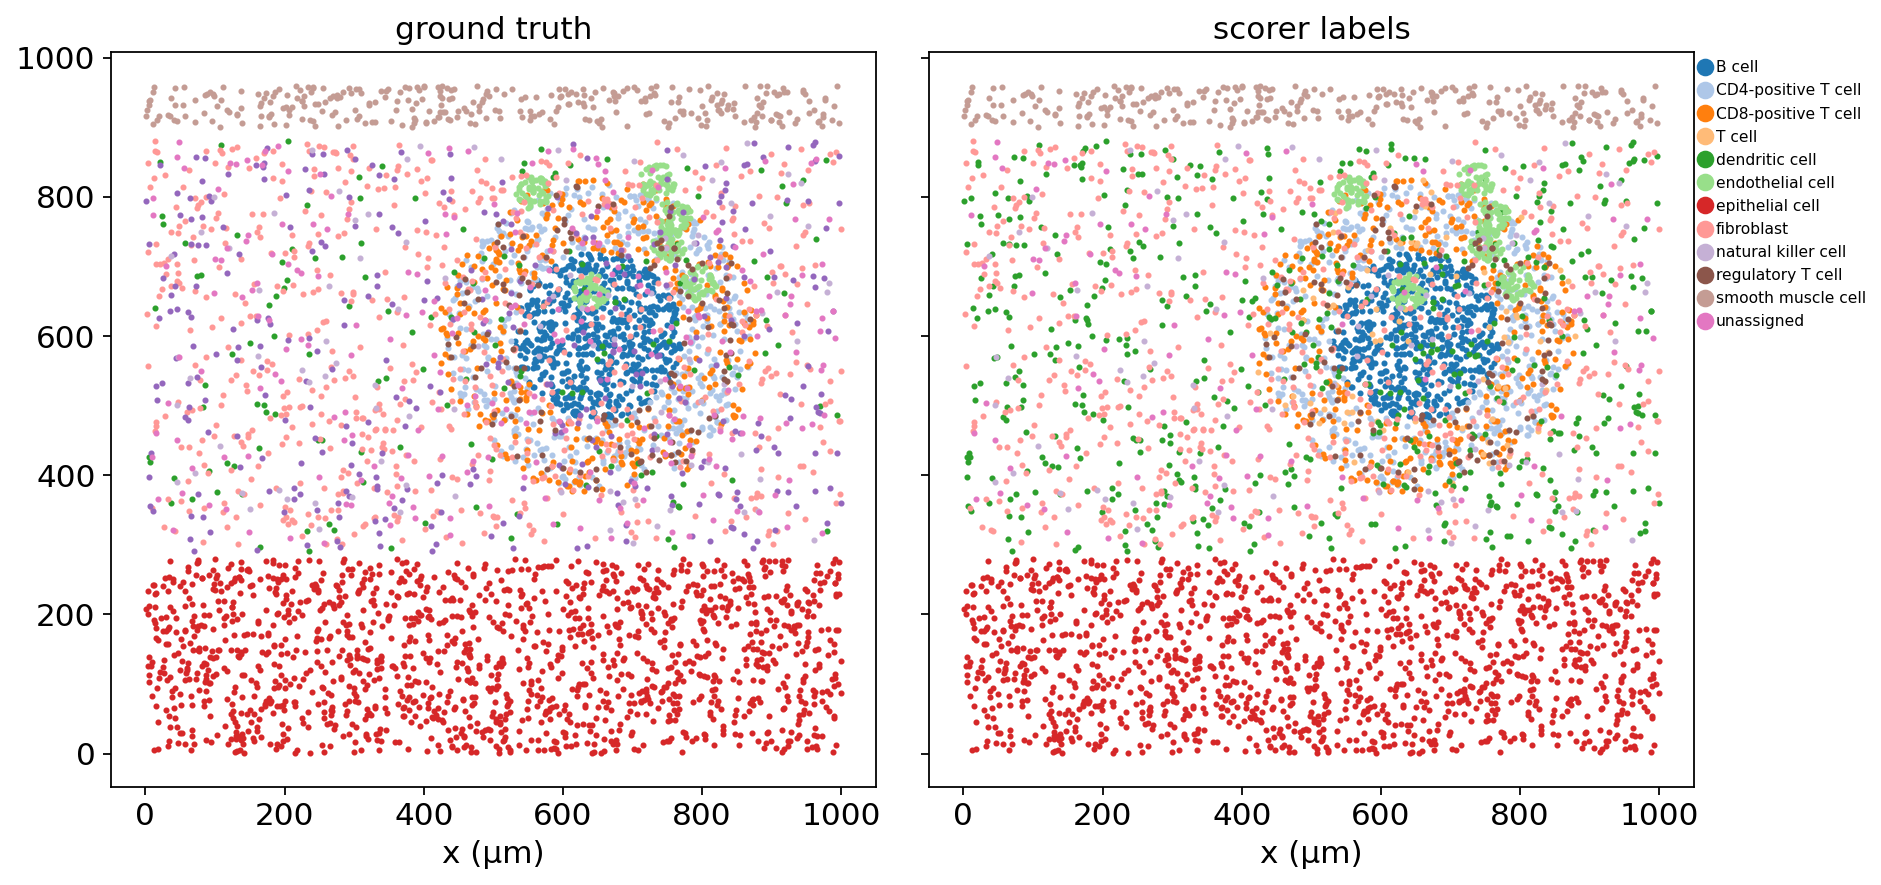

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), sharey=True)
labs = sorted(set(cells['label']) | set(cell_truth))
pal2 = dict(zip(labs, plt.cm.tab20.colors))
for ax, col, title in [(axes[0], cell_truth, 'ground truth'), (axes[1], cells['label'], 'scorer labels')]:
    for t in labs:
        m = (col == t).to_numpy()
        if m.any():
            ax.scatter(cells.x[m], cells.y[m], s=3, color=pal2[t], label=t)
    ax.set_aspect('equal'); ax.set_title(title); ax.set_xlabel('x (µm)')
axes[1].legend(markerscale=4, fontsize=7, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

## 7. Spatial context as evidence: `cluster_neighbor_composition`

A label is more credible when the cluster sits where that cell type lives.
`cluster_neighbor_composition` averages, over each cluster's cells, the
label mix of their neighbours within a radius (default 3 × the median
nearest-neighbour distance; neighbourhoods never cross `samples`).

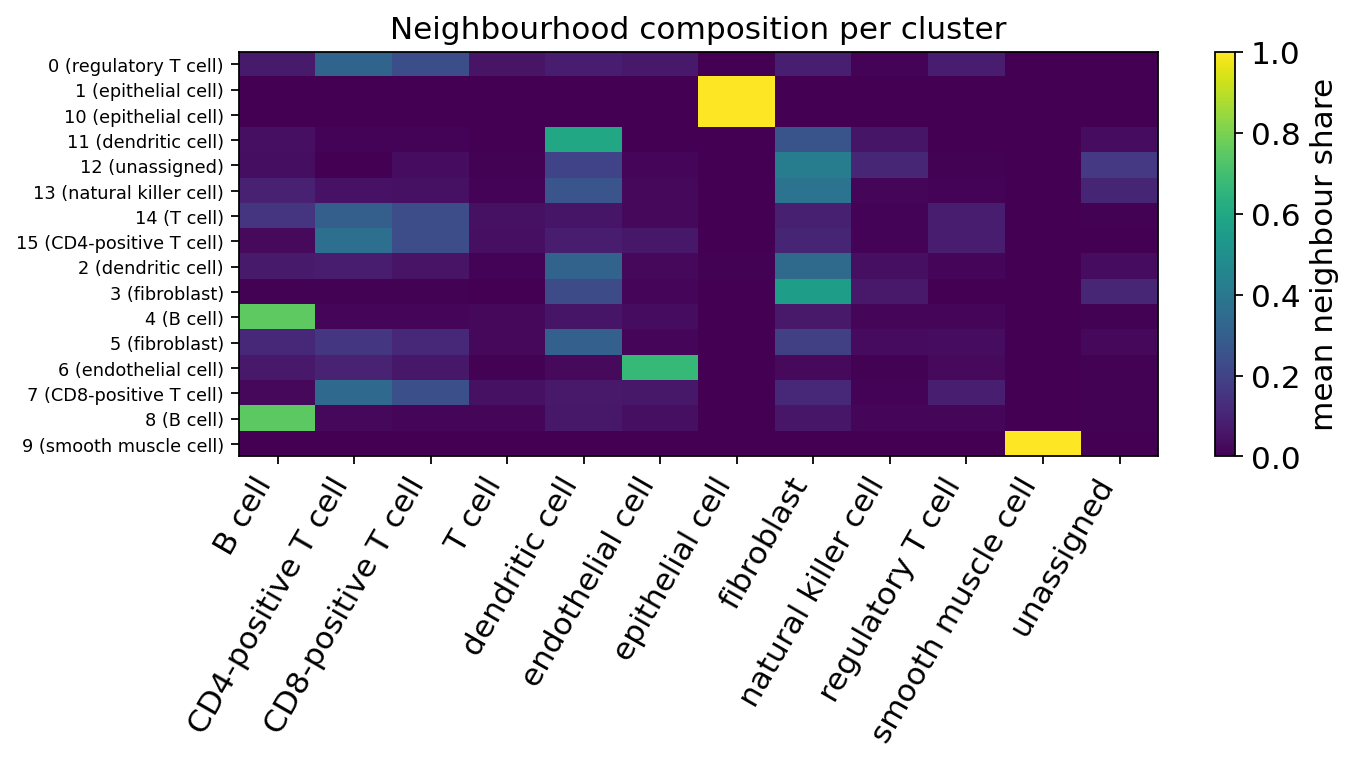

In [15]:
nc = ov.space.cluster_neighbor_composition(cells[['x', 'y']].to_numpy(), cells['cluster'],
                                           labels=res['label'].to_dict())
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(nc.values, cmap='viridis', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(nc.shape[1])); ax.set_xticklabels(nc.columns, rotation=60, ha='right')
ax.set_yticks(range(nc.shape[0]))
ax.set_yticklabels([f'{c} ({res.at[c, "label"]})' for c in nc.index], fontsize=8)
fig.colorbar(im, ax=ax, label='mean neighbour share')
ax.set_title('Neighbourhood composition per cluster')
plt.tight_layout(); plt.show()

The composition is a consistency check, not a second classifier: the
T-cell clusters border the B-cell follicle, macrophage and fibroblast
clusters share the stroma, the epithelium is surrounded by itself. A
cluster whose neighbourhood contradicts its label is the first one to
re-examine.

The scorer can also *use* it. A residual cluster may take a label from
`residual_alternatives` when that label dominates its surroundings
(`residual_ratio` × the residual share, default 2). By default only labels
the panel cannot test positively (weak or empty signatures) qualify —
lacking a testable label's markers is evidence *against* it. Here the
`unassigned` cells are scattered through the stroma and their neighbours
are mostly other stromal types, so we can check that the default keeps them
unassigned instead of forcing them into `fibroblast`:

In [16]:
first = ov.space.score_cluster_signatures(prof, kb['signatures'], parents=kb['parents'],
                                          polar=kb['polar'], defining=kb['defining'],
                                          residual_label='unassigned')
nc_first = ov.space.cluster_neighbor_composition(cells[['x', 'y']].to_numpy(), cells['cluster'],
                                                 labels=first['top_label'].fillna('unassigned').to_dict())
res_nb = ov.space.score_cluster_signatures(
    prof, kb['signatures'], parents=kb['parents'], polar=kb['polar'], defining=kb['defining'],
    residual_label='unassigned', neighbor_composition=nc_first,
    residual_alternatives=['fibroblast', 'smooth muscle cell'])
resid = res.index[res['label'] == 'unassigned']
pd.DataFrame({'without context': res.loc[resid, 'label'],
              'with context': res_nb.loc[resid, 'label'],
              'neighbour share: unassigned': nc_first.loc[resid, 'unassigned'].round(2),
              'neighbour share: fibroblast': nc_first.loc[resid, 'fibroblast'].round(2),
              'neighbour share: smooth muscle': nc_first.loc[resid].get('smooth muscle cell', 0).round(2)})

   without context with context  neighbour share: unassigned  \
12      unassigned   unassigned                         0.17   

    neighbour share: fibroblast  neighbour share: smooth muscle  
12                         0.43                             0.0  

The `unassigned` cluster's neighbours are 43 % fibroblasts and only 17 %
its own kind — a share large enough to pass `residual_ratio` — yet it stays
unassigned: `fibroblast` has a usable signature that this cluster does not
express, and lacking a label's markers is evidence against that label. Pass
`residual_to_testable=True` only when you have a reason to trust location
over markers.

## 8. The deliverable and its audit trail: `write_cluster_labels` / `audit_cluster_labels`

The cluster → label table is written **directly from the scorer result**,
in whatever column layout the downstream consumer expects. A manual change
is possible only as an `override = {cluster: (label, evidence)}`, it must
state the marker evidence, and it is accepted only for clusters whose
review is `open`. Overrides of `fixed` clusters are refused — the point is
that a person cannot quietly overrule strong evidence. Everything goes to a
sidecar `<name>.audit.csv`.

We review every cluster with the evidence the scorer reports (the
`candidates` column and the profile z-scores) and propose two kinds of
change:

* an open stromal cluster where the smooth-muscle candidate has a strong
  aSMA z, but Podoplanin and Vimentin are as high and the cells sit in the
  stroma, not the muscle layer: we **confirm** `fibroblast` (an override
  equal to the scorer's label is recorded as a confirmation);
* clusters with **no stand-out marker at all**: we propose the descriptive
  residual name `other stromal`, with the evidence. This is accepted for
  the clusters the scorer left open — and refused for the one it fixed.

In [17]:
z = prof.filter(like='z:').rename(columns=lambda c: c[2:])
print('open clusters:', [c for c in res.index if str(res.at[c, 'review']).startswith('open')])
overrides = {}
for c in res.index:
    if not prof.attrs['standout'][c]:
        overrides[c] = ('other stromal', f"no stand-out marker (max z={z.loc[c].max():.1f}); "
                                         "cells scattered through the stroma")
    elif res.at[c, 'label'] == 'fibroblast' and str(res.at[c, 'review']).startswith('open'):
        overrides[c] = ('fibroblast', f"Podoplanin z={z.at[c, 'Podoplanin']:.1f}, "
                                      f"Vimentin z={z.at[c, 'Vimentin']:.1f} with aSMA "
                                      f"z={z.at[c, 'aSMA']:.1f}; stromal location")
pd.Series({c: v[0] for c, v in overrides.items()}, name='proposed').to_frame()

open clusters: ['11', '12', '3']


         proposed
11  other stromal
12  other stromal
14  other stromal
3      fibroblast

In [18]:
os.makedirs('results', exist_ok=True)
table, diff = ov.space.write_cluster_labels(res, 'results/cluster_annotations.csv',
                                            columns=('cluster', 'cell_type'),
                                            overrides=overrides)
table.head()

[write_cluster_labels] override of cluster 14 -> 'other stromal' refused: the scorer marked it 'fixed'; keeping 'T cell'
[write_cluster_labels] wrote 16 rows to results/cluster_annotations.csv; 2 accepted override(s); audit results/cluster_annotations.audit.csv


   cluster          cell_type
0        0  regulatory T cell
1        1    epithelial cell
2        2     dendritic cell
3        3         fibroblast
4        4             B cell

In [19]:
pd.read_csv('results/cluster_annotations.audit.csv')[['cluster', 'scorer_label', 'written_label',
                                                       'source', 'review', 'evidence']]

    cluster         scorer_label        written_label  \
0         0    regulatory T cell    regulatory T cell   
1         1      epithelial cell      epithelial cell   
2         2       dendritic cell       dendritic cell   
3         3           fibroblast           fibroblast   
4         4               B cell               B cell   
5         5           fibroblast           fibroblast   
6         6     endothelial cell     endothelial cell   
7         7  CD8-positive T cell  CD8-positive T cell   
8         8               B cell               B cell   
9         9   smooth muscle cell   smooth muscle cell   
10       10      epithelial cell      epithelial cell   
11       11       dendritic cell        other stromal   
12       12           unassigned        other stromal   
13       13  natural killer cell  natural killer cell   
14       14               T cell               T cell   
15       15  CD4-positive T cell  CD4-positive T cell   

                      source  

The audit file records, for every cluster, what the scorer said, what was
written, why, and the review state: the confirmed stromal cluster is logged
as `scorer (override equal)`; the two open featureless clusters now read
`other stromal`, each with its evidence (the one the scorer had called
`dendritic cell` is thereby corrected); the featureless cluster the scorer
had **fixed** as `T cell` keeps that label — `override refused (fixed)`.
The review threshold cannot be loosened (`review_below` only accepts
stricter values), so the remedy for that cluster is upstream: merge or
re-cluster featureless cells before scoring.

`audit_cluster_labels` re-reads a deliverable and lists every row that is
not the scorer's call or a recorded override. The file we just wrote is
clean; then we simulate a later hand edit:

In [20]:
print('problems in the written file:', len(ov.space.audit_cluster_labels(
    'results/cluster_annotations.csv', res, columns=('cluster', 'cell_type'))))

edited = pd.read_csv('results/cluster_annotations.csv')
edited.loc[edited.index[-1], 'cell_type'] = 'macrophage'          # silent manual edit
edited = edited.iloc[1:]                                            # and a dropped row
edited.to_csv('results/cluster_annotations_edited.csv', index=False)
import shutil                                                       # the edit keeps the audit sidecar
shutil.copy('results/cluster_annotations.audit.csv', 'results/cluster_annotations_edited.audit.csv')
ov.space.audit_cluster_labels('results/cluster_annotations_edited.csv', res,
                              columns=('cluster', 'cell_type'))

[audit_cluster_labels] 0 unrecorded difference(s) in results/cluster_annotations.csv
problems in the written file: 0
[audit_cluster_labels] 2 unrecorded difference(s) in results/cluster_annotations_edited.csv
group cluster        scorer_label file_label                                         problem
 None       0   regulatory T cell       None                                         missing
 None      15 CD4-positive T cell macrophage differs from scorer without a recorded override


  group cluster         scorer_label  file_label  \
0  None       0    regulatory T cell        None   
1  None      15  CD4-positive T cell  macrophage   

                                           problem  
0                                          missing  
1  differs from scorer without a recorded override  

Both the unrecorded relabel and the missing cluster are reported. Run the
audit as the last step of a pipeline (or in CI) and a deliverable can never
drift from the evidence without a trace.

## 8b. When the evidence conflicts: `fixed`, `resolved` and `open`

A first-pass call can be contested in two ways: the winner leads on its
**whole signature** while another candidate leads on **one defining
marker** (typically spill-over of a bright neighbour's marker, or a broadly
expressed marker), or the winner's own defining marker is not elevated at
all. A reviewer who settles every such case by eye tends to follow the single
marker — and is wrong whenever that marker is spill-over. The scorer
therefore settles the cases the evidence settles and says so:

* `fixed` — the winner's best defining marker (`lineage_z`) is at or above
  the dataset mean and no other candidate's (`alt_lineage_z`, `alt_label`)
  is higher;
* `resolved: keep …` — the conflict is decided, with the numbers in the
  text: another candidate leads only on its single best defining marker
  while the winner leads on the whole signature (single-marker switches are
  the rule of `defining_check`, already applied); or, with a label of
  exclusion, the winner is weak but no candidate reaches the mean (the
  presence test already decided it);
* `open: …` — the winner is below the dataset mean while another
  candidate reaches it (or, without a label of exclusion, nobody does), or
  no label's markers are present at all (the label of exclusion is then a
  default, not evidence): the only clusters a reviewer may change.

A small self-contained example with arbitrary lineages: `lin_A` is a broad
three-marker programme, `lin_B` rests on one defining marker that also
spills into neighbouring cells, `other` is the label of exclusion.

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np
import pandas as pd
import omicverse as ov

rng = np.random.default_rng(3)
markers = ['a1', 'a2', 'a3', 'b1', 'b2']
spec = {'A_bright': dict(a1=1.0, a2=0.9, a3=0.8),
        'A_spill':  dict(a1=0.5, a2=0.5, a3=0.45, b1=0.7),   # A programme + B spill-over
        'mixed':    dict(a1=0.05, a2=0.6, a3=0.6, b1=0.45),  # A without its defining marker
        'B':        dict(b1=1.0, b2=0.8),
        'B_weak':   dict(b1=0.25, b2=0.1, a1=0.12),           # dim
        'quiet1': {}, 'quiet2': {}, 'quiet3': {}}
toy = pd.concat([pd.DataFrame({m: np.clip(rng.normal(mu.get(m, 0.05), 0.08, 300), 0, None)
                               for m in markers}).assign(cluster=cl)
                 for cl, mu in spec.items()], ignore_index=True)
toy_sigs = {'lin_A': {'a1': 1.0, 'a2': 0.8, 'a3': 0.8}, 'lin_B': {'b1': 1.0, 'b2': 0.4}}
toy_def = {'lin_A': ['a1'], 'lin_B': ['b1']}
toy_prof = ov.space.cluster_marker_profile(toy, 'cluster', markers=markers)
toy_res = ov.space.score_cluster_signatures(toy_prof, toy_sigs, defining=toy_def,
                                            residual_label='other')
toy_res[['label', 'score', 'lineage_z', 'alt_label', 'alt_lineage_z']].round(2)

          label  score  lineage_z alt_label  alt_lineage_z
A_bright  lin_A   3.61       2.37      None            NaN
A_spill   lin_A   1.24       0.81     lin_B           1.09
B         lin_B   2.85       2.02      None            NaN
B_weak    other    NaN        NaN      None            NaN
mixed     lin_A   0.76      -0.57     lin_B           0.36
quiet1    other    NaN        NaN      None            NaN
quiet2    other    NaN        NaN      None            NaN
quiet3    other    NaN        NaN      None            NaN

In [2]:
for c in toy_res.index:
    print(f'{c:9s}', toy_res.at[c, 'review'])

A_bright  fixed
A_spill   resolved: keep lin_A - whole-signature score 1.24 vs lin_B 0.87; lin_B leads only on its best single defining marker (z=1.1 vs 0.8); a single defining marker switches the call only when the winner's defining markers stay below z=0.5 and the other's reach z=1.5 (defining-marker check, applied)
B         fixed
B_weak    open: no signature present - no label's markers reach presence (other, or a neighbourhood alternative); change only to a label whose own markers you can cite
mixed     open: winner evidence z=-0.6 below 0.0; lin_B evidence z=0.4 reaches it
quiet1    open: no signature present - no label's markers reach presence (other, or a neighbourhood alternative); change only to a label whose own markers you can cite
quiet2    open: no signature present - no label's markers reach presence (other, or a neighbourhood alternative); change only to a label whose own markers you can cite
quiet3    open: no signature present - no label's markers reach presence (othe

* `A_spill` expresses the whole `lin_A` programme; its `b1` is spill-over
  that happens to sit a little higher (z 1.1 vs 0.8 for `a1`). The
  whole-signature score favours `lin_A` clearly and `b1` does not pass the
  defining-marker check, so the call is **resolved**, not open — the
  single marker is not a reason to switch.
* `mixed` lacks `lin_A`'s defining marker (z below the mean) while
  `lin_B`'s reaches it: a genuine conflict, left **open** for review.
* The dim and quiet clusters carry no label's markers above background:
  they take the label of exclusion `other` but stay **open** — a default,
  which a reviewer may change only on a stand-out marker that the knowledge
  base lists for another label.

Changes through `lineage=` apply to open clusters only; for the others they
are ignored and the reason says why:

In [3]:
chg = ov.space.score_cluster_signatures(
    toy_prof, toy_sigs, defining=toy_def, residual_label='other',
    lineage={'A_bright': 'lin_B', 'A_spill': 'lin_B', 'mixed': 'lin_B'})
chg.loc[['A_bright', 'A_spill', 'mixed'], ['label', 'reason']]

          label                                             reason
A_bright  lin_A  lin_A 3.61; lineage change to 'lin_B' ignored:...
A_spill   lin_A  lin_A 1.24 > lin_B 0.87; lineage change to 'li...
mixed     lin_B                               lineage given: lin_B

`write_cluster_labels` recomputes the same states from `lineage_z`,
`alt_lineage_z` and `label_of_exclusion` (whatever the scorer was called
with) and accepts evidenced overrides for open clusters only:

In [4]:
import os, tempfile
out = os.path.join(tempfile.mkdtemp(), 'toy_annotations.csv')
tab, diff = ov.space.write_cluster_labels(
    toy_res, out, columns=('cluster', 'cell_type'),
    overrides={'A_spill': ('lin_B', 'b1 z=1.1 above a1 z=0.8'),
               'mixed': ('lin_B', 'a1 z=-0.6 (absent); b1 z=0.4, b2 elevated')})
pd.read_csv(out.replace('.csv', '.audit.csv'))[['cluster', 'scorer_label', 'written_label',
                                                'source', 'review']]

[write_cluster_labels] override of cluster A_spill -> 'lin_B' refused: the scorer marked it 'resolved: winner leads on the whole signature; another candidate leads only on one defining marker (z=1.1 vs 0.8)'; keeping 'lin_A'
[write_cluster_labels] wrote 8 rows to /tmp/tmpq2zciram/toy_annotations.csv; 1 accepted override(s); audit /tmp/tmpq2zciram/toy_annotations.audit.csv
[write_cluster_labels] 1 override(s) refused: those clusters are fixed or resolved by the evidence and keep the scorer's label. This file is the deliverable - do not rewrite it by other means; put any disagreement, with its numbers, in the report.


    cluster scorer_label written_label                       source  \
0  A_bright        lin_A         lin_A                       scorer   
1   A_spill        lin_A         lin_A  override refused (resolved)   
2         B        lin_B         lin_B                       scorer   
3    B_weak        other         other                       scorer   
4     mixed        lin_A         lin_B                     override   
5    quiet1        other         other                       scorer   
6    quiet2        other         other                       scorer   
7    quiet3        other         other                       scorer   

                                              review  
0                                              fixed  
1  resolved: winner leads on the whole signature;...  
2                                              fixed  
3                         open: no signature present  
4  open: winner evidence z=-0.6 below 0.0; anothe...  
5                         open

Only the open cluster changed. The practical rule for a reviewer —
human or agent — is: the deliverable is the scorer's labels; fixed and
resolved calls are final (if you disagree, write it in the report with the
numbers); change open clusters only, through `lineage=` or `overrides` with
the evidence. (The `review` texts printed in sections 6 and 8 above were
produced by an earlier version of the scorer, which flagged single-marker
conflicts as `open`; re-running them now shows those clusters as
`resolved`.)

## 8c. Lineage, specificity and contrast: three ways a call goes wrong on a real panel

Three failure modes show up as soon as a panel is applied to real tissue,
and each has a data-driven remedy in the knowledge base or in the panel
itself — no marker list is written by hand:

1. **A state label without its lineage.** Some labels are defined by a
   *state* marker rather than a lineage marker — a proliferating T cell is
   defined in the literature by Ki-67, a marker every dividing cell
   carries. A Ki-67-high tumour cluster then looks like the state label.
   `markerdb_signatures` returns `kb['lineage_markers']`: for each label,
   the defining markers of its **Cell Ontology ancestors** that the label's
   own atlas entry also lists (for a cycling T cell: the T-cell marker),
   keeping only markers that define some label of the set and that most
   labels do not carry (a pan-leukocyte antigen separates nothing). Passed
   to the scorer as `lineage_markers=`, a label is not a candidate in a
   cluster where **all** its lineage markers are below their background
   level — the level most clusters carry. The same pass stops inheriting an
   ancestor's marker that defines *another* subtype of that ancestor
   (`subtype_markers=True`): a CD4 T cell does not inherit CD8 from
   "mature αβ T cell".
2. **A single-marker conflict.** The whole-signature winner and another
   candidate each have one stand-out defining marker. Which one to trust
   depends on two properties the data provide: the marker's
   **specificity across the label set's lineages** (computed from the
   signatures: the largest lineage's share of the marker's weight — a Fc
   receptor carried by NK cells, monocytes and neutrophils scores low) and
   its **contrast on this panel** (the share of the brightest cluster mean
   above the marker's background — an antibody that stains every cluster
   almost as much as its target has little). The other candidate takes the
   cluster only when all its defining markers on that path are at or above
   the mean (coherent evidence) and its specificity × contrast weighted
   evidence is larger; otherwise the call is
   `resolved: keep ...`. The defining-marker check compares candidates on
   contrast-weighted evidence too.
3. **Subtypes compared on what they share.** Subtype signatures inherit
   their parent's markers, so two siblings that differ by one weakly
   weighted marker look alike on their whole signatures. Splits now compare
   children on their **increments** over the parent (the markers they weigh
   more than the parent does).

A self-contained example with arbitrary names. `t` is a lineage marker,
`k` a state marker, `h` the marker of a tumour-like label, `s` a marker
with high background in every cluster; `MO`/`MA` are two lineages whose
subtypes rest on a shared (`sh`) and a specific (`r`) marker.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import omicverse as ov

def simulate(spec, markers, n=150, seed=3):
    # cells x markers; each cluster's mean per marker from spec (0.02 otherwise)
    rng = np.random.default_rng(seed)
    return pd.concat([pd.DataFrame({m: np.clip(rng.normal(mu.get(m, 0.02), 0.04, n), 0, None)
                                    for m in markers}).assign(cluster=cl)
                      for cl, mu in spec.items()], ignore_index=True)

# 1. a state label (TK: state marker k, lineage marker t) vs a tumour-like label H
mk1 = ['t', 'k', 'h']
spec1 = {'T_bright': dict(t=0.8), 'bg1': dict(t=0.2), 'bg2': dict(t=0.2), 'bg3': dict(t=0.2),
         'dividing_H': dict(k=0.8, h=0.3, t=0.0), 'H': dict(h=0.8, t=0.2)}
prof1 = ov.space.cluster_marker_profile(simulate(spec1, mk1), 'cluster')
sigs1 = {'TK': {'k': 1.0, 't': 0.15}, 'H': {'h': 1.0}, 'T': {'t': 1.0}}
def1 = {'TK': ['k'], 'H': ['h'], 'T': ['t']}
without = ov.space.score_cluster_signatures(prof1, sigs1, defining=def1)
with_lm = ov.space.score_cluster_signatures(prof1, sigs1, defining=def1,
                                           lineage_markers={'TK': ['t']})
pd.DataFrame({'t (z)': prof1['z:t'].round(1), 'k (z)': prof1['z:k'].round(1),
              'h (z)': prof1['z:h'].round(1),
              'without lineage_markers': without['label'],
              'with lineage_markers': with_lm['label']})

            t (z)  k (z)  h (z) without lineage_markers with lineage_markers
H            -0.3   -0.5    2.1                       H                    H
T_bright      2.1   -0.4   -0.6                       T                    T
bg1          -0.3   -0.5   -0.6              unassigned           unassigned
bg2          -0.3   -0.4   -0.6              unassigned           unassigned
bg3          -0.3   -0.4   -0.6              unassigned           unassigned
dividing_H   -1.0    2.2    0.4                      TK                    H

`dividing_H` is bright on the state marker `k` and moderately on `h`. On
its whole signature the state label `TK` wins; but the cluster's lineage
marker `t` is below the level every other cluster carries, so with
`lineage_markers` the state label is not a candidate there and the call
goes to `H`. `T_bright`, which carries `t`, is unaffected.

**2. A single-marker conflict.** In `x`, `MO` wins on the whole signature
through its subtype `MO_c`, whose defining marker `sh` is shared with a
third lineage `N`; `MA`'s subtype marker `r` is specific to `MA` and stands
out more. In `y`, the competitor `S` also stands out on one marker, but its
second defining marker is below the mean (incoherent evidence):

In [2]:
sigs2 = {'MO': {'p': 1.0}, 'MO_c': {'p': 1.0, 'sh': 1.0},
         'MA': {'q': 1.0, 'r': 0.3}, 'MA_c': {'r': 1.0, 'q': 0.3},
         'S': {'v': 1.0, 'w': 1.0}, 'N': {'sh': 1.0}, 'O': {'o': 1.0}}
par2 = {'MO_c': 'MO', 'MA_c': 'MA'}
def2 = {'MO': ['p'], 'MO_c': ['sh'], 'MA': ['q'], 'MA_c': ['r'], 'S': ['v', 'w'],
        'N': ['sh'], 'O': ['o']}
others = {'n1': dict(sh=0.6), 'mo1': dict(p=0.8), 'o1': dict(o=0.8), 'o2': dict(o=0.5)}
panels2 = {   # two small panels, one conflict each
    'x': {'x': dict(p=0.75, sh=0.9, q=0.3, r=0.85), 'ma1': dict(q=0.8, r=0.3), 'e': {}, **others},
    'y': {'y': dict(p=0.75, sh=0.9, v=0.85), 's1': dict(v=0.5, w=0.8), 'e': dict(w=0.3), **others}}
for c, spec in panels2.items():
    pr = ov.space.cluster_marker_profile(simulate(spec, ['p', 'sh', 'q', 'r', 'v', 'w', 'o']), 'cluster')
    on = ov.space.score_cluster_signatures(pr, sigs2, parents=par2, defining=def2)
    off = ov.space.score_cluster_signatures(pr, sigs2, parents=par2, defining=def2, switch_rule='none')
    print(f'{c}: switch_rule="none" -> {off.at[c, "label"]:5s}| default -> {on.at[c, "label"]}')
    print('   reason:', on.at[c, 'reason'])
    print('   review:', on.at[c, 'review'][:160])

x: switch_rule="none" -> MO_c | default -> MA_c
   reason: MA 2.35 > MO 2.48; single-marker conflict: MO -> MA (specificity x contrast weighted lineage evidence 2.23 vs 1.46); split of MA: MA_c
   review: fixed
y: switch_rule="none" -> MO_c | default -> MO_c
   reason: MO 2.48 > N 1.99; split of MO: MO_c
   review: resolved: keep MO - whole-signature score 2.48 vs S 1.07; S leads only on its best single defining marker (z=2.1 vs 2.0); a single defining marker switches the 


In `x` the conflict is settled for `MA`: its evidence `r` is coherent, and
after weighting each marker by its specificity (shared `sh` counts less)
and its contrast on the panel, `MA`'s evidence is larger; the subtype
split then gives `MA_c`. In `y` the alternative `S` leads on `v` alone
while its other defining marker `w` is below the mean, so the winner is
kept and the review says why. A reviewer reads both outcomes in `reason`
/ `review`; neither is open to re-adjudication.

The specificity and contrast are not settings — they are measured. The
contrast of each marker on a panel can be read off the profile:

In [3]:
from omicverse.space._cluster_signature import _background
mk3 = ['a', 'b', 'c', 's', 'm']
base = dict(s=0.5)                     # s: an antibody that stains every cluster
spec3 = {'x': dict(a=0.3, b=0.8, c=0.8, s=0.65, m=0.3), 'y': dict(base, m=0.2, a=0.3),
         'u': dict(base, a=0.6), 'v': dict(base, b=0.3), 'w': dict(base, c=0.3), 'z': dict(base)}
prof3 = ov.space.cluster_marker_profile(simulate(spec3, mk3), 'cluster')
contrast = {m: (prof3[f'mean:{m}'].max() - _background(prof3[f'mean:{m}'])) / prof3[f'mean:{m}'].max()
            for m in ['s', 'm']}
print('z in x       :', {m: round(prof3.at['x', f'z:{m}'], 2) for m in ['s', 'm']})
print('contrast     :', {m: round(v, 2) for m, v in contrast.items()})
sigs3 = {'X': {'a': 1.0, 'b': 1.0, 'c': 1.0}, 'P': {'s': 1.0}, 'M': {'m': 1.0}}
r3 = ov.space.score_cluster_signatures(prof3, sigs3, defining={'X': ['a'], 'P': ['s'], 'M': ['m']})
print('call for x   :', r3.at['x', 'label'], '|', r3.at['x', 'reason'])

z in x       : {'s': np.float64(2.23), 'm': np.float64(1.84)}
contrast     : {'s': np.float64(0.23), 'm': np.float64(0.91)}
call for x   : M | M 1.84 > X 2.66; defining-marker check: X (z 0.4) -> M (z 1.8)


`x`'s whole-signature winner `X` has its own defining marker `a` below
0.5, so the defining-marker check looks for the candidate whose defining
marker stands out. `s` has the larger z-score, but most of its signal is
the background every cluster carries (contrast ≈ 0.2); `m` is a clean
marker (contrast ≈ 0.9). Compared on contrast-weighted evidence, `M`
takes the cluster.

**3. Subtypes compared on their increments.** `x` and `y` are the two
clusters of lineage `P`. `C1` adds `g` to `P`'s marker; `C2` adds `g` and
`h`, each weakly. `x` and `y` differ most on the shared marker `p`, then on
`g`, least on `h`. Compared on whole signatures, the child that lists `p`
with the smallest share of other markers looks most separating — `C2`,
although `h`, the only thing `C2` adds beyond `g`, barely differs between
the two clusters; compared on what each child adds, `C1`'s `g` axis
separates them best:

In [4]:
mk4 = ['p', 'g', 'h', 'o']
spec4 = {'x': dict(p=0.9, g=0.6, h=0.4), 'y': dict(p=0.3, g=0.3, h=0.2),
         'o1': dict(o=0.8, g=0.5, h=0.6), 'o2': dict(o=0.6, h=0.5), 'o3': {}}
prof4 = ov.space.cluster_marker_profile(simulate(spec4, mk4), 'cluster')
sigs4 = {'P': {'p': 1.0}, 'C1': {'p': 1.0, 'g': 0.24}, 'C2': {'p': 1.0, 'g': 0.08, 'h': 0.08},
         'O': {'o': 1.0}}
kw4 = dict(parents={'C1': 'P', 'C2': 'P'}, defining={'P': ['p'], 'C1': ['p'], 'C2': ['p'], 'O': ['o']})
pd.DataFrame({'whole signature': ov.space.score_cluster_signatures(prof4, sigs4, split_axis='signature', **kw4)['label'],
              'increment (default)': ov.space.score_cluster_signatures(prof4, sigs4, **kw4)['label']}).loc[['x', 'y']]

  whole signature increment (default)
x              C2                  C1
y               P                   P

Only the brightest member is promoted (the other keeps the lineage
label), and the child chosen is the one whose own addition separates the
lineage's clusters — not the one that merely repeats the parent's marker
with a different second weight.

In practice all three behaviours are on by default; pass
`lineage_markers=kb['lineage_markers']` together with `parents`, `polar`
and `defining`:

```python
KW = dict(parents=kb['parents'], polar=kb['polar'], defining=kb['defining'],
          lineage_markers=kb['lineage_markers'])
res = ov.space.score_cluster_signatures(prof, kb['signatures'], **KW)
```

`switch_rule='none'` and `split_axis='signature'` restore the earlier
behaviour for comparison.

## 9. Pitfalls

* **Check the gene mapping before anything else.** `panel_gene_map`'s
  `sources` and `kb['gene_check']` / `kb['gene_review']` list indirect
  matches. A wrong paralogue (`aSMA` → *ACTA1*, section 3) does not raise
  an error; it silently weakens or redirects a signature. Fix nomenclature
  with `gene_overrides` / `protein_names` — never by writing cell-type
  markers by hand.
* **Unresolved and weak signatures.** `kb['unresolved_markers']` carry no
  evidence; `kb['weak_signatures']` are labels the panel cannot really test
  (their best marker is far weaker than a typical defining marker). They do
  not compete in the first pass — expect them as `unassigned` or as
  neighbourhood alternatives, and say so in the methods.
* **Ambiguous clusters are flagged, not hidden.** Read `review`,
  `lineage_z` and `candidates`. An `open` cluster can be overridden with
  evidence; a low-purity cluster usually needs better segmentation or more
  clusters instead.
* **Spill-over looks like co-expression.** Touching cells leak signal into
  each other's masks (here 15 %). Negative markers in the signatures and the
  background-relative presence test absorb part of it; do not lower the
  presence threshold to "rescue" a label.
* **One panel / one platform at a time.** `cluster_marker_profile` scales
  within a dataset; intensities from different panels or instruments are
  not comparable — profile and score them separately and combine the
  results with `write_cluster_labels({'d1': r1, 'd2': r2}, ...)`.
* **Vocabulary wording matters.** Labels are matched to atlas / CL terms;
  check `kb['resolved']` and `kb['unresolved_labels']`, and use
  `descriptions=` when a label is defined as a union of cell types.
* **Network and token.** The atlas marker endpoint needs
  `OMICOS_USER_TOKEN`; keep the `cache=` JSON with the analysis so the
  signatures used are frozen and reproducible.

## 10. References

* Goltsev Y. *et al.* Deep profiling of mouse splenic architecture with
  CODEX multiplexed imaging. *Cell* 174, 968–981 (2018).
  doi:10.1016/j.cell.2018.07.010
* Schürch C. M. *et al.* Coordinated cellular neighborhoods orchestrate
  antitumoral immunity at the colorectal cancer invasive front. *Cell* 182,
  1341–1359 (2020). doi:10.1016/j.cell.2020.07.005
* Hickey J. W. *et al.* Strategies for accurate cell type identification in
  CODEX multiplexed imaging data. *Front. Immunol.* 12, 727626 (2021).
  doi:10.3389/fimmu.2021.727626
* Bai Z. *et al.* Adjacent cell marker lateral spillover compensation and
  reinforcement for multiplexed images (REDSEA). *Front. Immunol.* 12,
  652631 (2021). doi:10.3389/fimmu.2021.652631
* Diehl A. D. *et al.* The Cell Ontology 2016: enhanced content,
  modularization, and ontology interoperability. *J. Biomed. Semantics* 7,
  44 (2016). doi:10.1186/s13326-016-0088-7
* Seal R. L. *et al.* Genenames.org: the HGNC resources in 2023. *Nucleic
  Acids Res.* 51, D1003–D1009 (2023). doi:10.1093/nar/gkac888
* Otsu N. A threshold selection method from gray-level histograms. *IEEE
  Trans. Syst. Man Cybern.* 9, 62–66 (1979). doi:10.1109/TSMC.1979.4310076